# Arithmetic Asian call: variance-reduction benchmark

Three estimators for the same arithmetic-average Asian call under GBM:

1. Plain Monte Carlo.
2. Antithetic variates: each shock vector $Z$ is paired with $-Z$, and the standard error is computed from the pair means.
3. Control variate: the geometric-average Asian payoff on the same paths, whose price is known in closed form (`price_geometric_asian`).

The notebook first checks the geometric closed form, then runs each estimator 20 times at five path counts and reports:

- standard error against $N$, and the variance reduction factor (VRF) against $N$;
- a headline table at $N = 64{,}000$: VRF, run time, and paths needed for a 1-cent 95% confidence half-width;
- a check that the control-variate price agrees with plain Monte Carlo.

All three estimators are the library functions used by the Streamlit app.

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

from mc_pricer.asian_geometric import price_geometric_asian
from mc_pricer.bs_analytics import bs_price
from mc_pricer.gbm import simulate_gbm_paths
from mc_pricer.mc import mc_price_asian_arithmetic
from mc_pricer.mc_results import build_result_iid, discount_payoffs
from mc_pricer.payoffs import asian_geometric_payoff
from mc_pricer.rng import RNG
from mc_pricer.variance_reduction import (
    mc_price_asian_arithmetic_antithetic,
    mc_price_asian_arithmetic_cv,
)

FIG_DIR = Path.cwd().parent / "docs" if Path.cwd().name == "notebooks" else Path("docs")
FIG_DIR.mkdir(exist_ok=True)
Z_95 = norm.ppf(0.975)
pd.set_option("display.precision", 5)

## Contract and settings

In [2]:
S0, K, r, T, sigma = 100.0, 95.0, 0.015, 1.0, 0.25
steps = 64  # equally spaced averaging dates; S0 itself is not in the average
n_grid = [1_000, 4_000, 16_000, 64_000, 256_000]
n_replications = 20
master_seed = 20260215
headline_N = 64_000
target_halfwidth = 0.01  # one cent

## Check the control's closed form

The control variate is only unbiased if its expectation is right. Two checks: with one averaging date the geometric Asian is a European option, so the formula must return Black-Scholes; with 64 dates it must match a 1-million-path simulation of the geometric payoff.

In [3]:
one_date = price_geometric_asian(100.0, 100.0, 0.05, 0.2, 1.0, 1, "call")
bs = bs_price(100.0, 100.0, 1.0, 0.05, 0.2, "call")
print(f"1 date:   closed form {one_date:.6f}   Black-Scholes {bs:.6f}")

geo_closed = price_geometric_asian(S0, K, r, sigma, T, steps, "call")
paths = simulate_gbm_paths(S0, r, sigma, T, steps, 1_000_000, rng=RNG(seed=1))
geo_mc = build_result_iid(discount_payoffs(asian_geometric_payoff(paths, K, "call"), r, T))
del paths
z = (geo_mc["price"] - geo_closed) / geo_mc["stderr"]
print(
    f"64 dates: closed form {geo_closed:.4f}   "
    f"MC {geo_mc['price']:.4f} +/- {geo_mc['stderr']:.4f}   z = {z:+.2f}"
)
assert abs(z) < 3

1 date:   closed form 10.450584   Black-Scholes 10.450584


64 dates: closed form 8.5526   MC 8.5435 +/- 0.0108   z = -0.84


## Benchmark

Each replication uses one seed for all three methods. Antithetic runs count both members of each pair in $N$, so every method uses $N$ simulated paths. Times are wall-clock per run and include path simulation.

In [4]:
def run_plain(N, rng):
    paths = simulate_gbm_paths(S0, r, sigma, T, steps, N, rng=rng)
    return mc_price_asian_arithmetic(paths, K, r, T, "call")


def run_antithetic(N, rng):
    return mc_price_asian_arithmetic_antithetic(S0, K, r, T, sigma, steps, N, rng, "call")


def run_cv(N, rng):
    return mc_price_asian_arithmetic_cv(S0, K, r, T, sigma, steps, N, rng, "call")


methods = {"plain": run_plain, "antithetic": run_antithetic, "control variate": run_cv}

seed_rng = np.random.default_rng(master_seed)
records = []
for N in n_grid:
    for seed in seed_rng.integers(1, 2**31 - 1, size=n_replications):
        for name, fn in methods.items():
            t0 = perf_counter()
            res = fn(N, RNG(seed=int(seed)))
            records.append(
                {
                    "method": name,
                    "N": N,
                    "price": res["price"],
                    "stderr": res["stderr"],
                    "time_s": perf_counter() - t0,
                }
            )
bench = pd.DataFrame(records)

summary = bench.groupby(["method", "N"]).agg(
    mean_price=("price", "mean"),
    mean_stderr=("stderr", "mean"),
    sd_of_prices=("price", "std"),
    mean_time_s=("time_s", "mean"),
)
plain = summary.loc["plain"]
summary["vrf_reported"] = summary["mean_stderr"].rdiv(plain["mean_stderr"], level="N") ** 2
summary["vrf_empirical"] = summary["sd_of_prices"].rdiv(plain["sd_of_prices"], level="N") ** 2
summary

mean_price  mean_stderr  sd_of_prices  mean_time_s  \
method          N                                                            
antithetic      1000       8.79366      0.22310       0.23120      0.00129   
                4000       8.90503      0.11183       0.12947      0.00714   
                16000      8.86945      0.05570       0.03337      0.03136   
                64000      8.87357      0.02796       0.03095      0.11951   
                256000     8.87813      0.01399       0.01240      0.55108   
control variate 1000       8.87713      0.01033       0.01051      0.00229   
                4000       8.87994      0.00541       0.00574      0.01065   
                16000      8.87861      0.00267       0.00298      0.04454   
                64000      8.87913      0.00135       0.00116      0.16787   
                256000     8.87916      0.00067       0.00072      0.79624   
plain           1000       8.78623      0.35032       0.36197      0.00167   
                4000       8.85038      0.17764       0.22509      0.00874   
                16000      8.88302      0.08849       0.07919      0.03576   
                64000      8.87221      0.04424       0.04266      0.14321   
                256000     8.88250      0.02216       0.02432      0.62639   

                        vrf_reported  vrf_empirical  
method          N                                    
antithetic      1000         2.46578        2.45104  
                4000         2.52297        3.02279  
                16000        2.52410        5.63223  
                64000        2.50431        1.89959  
                256000       2.50966        3.84511  
control variate 1000      1151.15019     1187.20864  
                4000      1079.69163     1539.94614  
                16000     1094.61726      706.31363  
                64000     1077.18233     1343.32867  
                256000    1084.79483     1143.87060  
plain           1000         1.00000        1.00000  
                4000         1.00000        1.00000  
                16000        1.00000        1.00000  
                64000        1.00000        1.00000  
                256000       1.00000        1.00000

`vrf_reported` is $(\text{plain stderr} / \text{method stderr})^2$ from the standard errors each run reports. `vrf_empirical` is the ratio of the variances of the 20 price estimates across replications. If the reported standard errors are right, the two agree up to the noise of a 20-sample variance (roughly $\pm 30\%$).

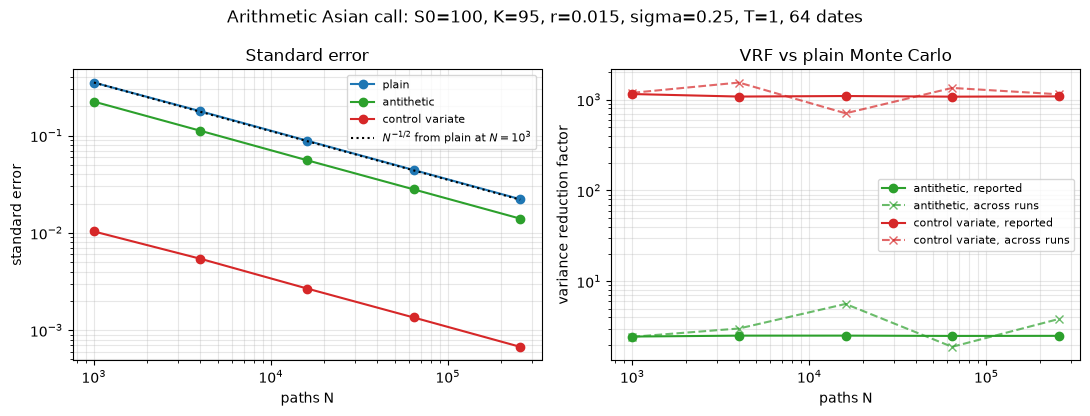

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
colors = {"plain": "tab:blue", "antithetic": "tab:green", "control variate": "tab:red"}
for name in methods:
    s = summary.loc[name]
    ax1.loglog(s.index, s["mean_stderr"], "o-", color=colors[name], label=name)
ref = plain["mean_stderr"].iloc[0] * np.sqrt(n_grid[0] / np.asarray(n_grid))
ax1.loglog(n_grid, ref, "k:", label=r"$N^{-1/2}$ from plain at $N=10^3$")
ax1.set_xlabel("paths N")
ax1.set_ylabel("standard error")
ax1.set_title("Standard error")
ax1.grid(True, which="both", alpha=0.3)
ax1.legend(fontsize=8)

for name in ("antithetic", "control variate"):
    s = summary.loc[name]
    ax2.semilogx(s.index, s["vrf_reported"], "o-", color=colors[name], label=f"{name}, reported")
    ax2.semilogx(
        s.index,
        s["vrf_empirical"],
        "x--",
        color=colors[name],
        alpha=0.7,
        label=f"{name}, across runs",
    )
ax2.set_yscale("log")
ax2.set_xlabel("paths N")
ax2.set_ylabel("variance reduction factor")
ax2.set_title("VRF vs plain Monte Carlo")
ax2.grid(True, which="both", alpha=0.3)
ax2.legend(fontsize=8)
fig.suptitle(
    f"Arithmetic Asian call: S0={S0:g}, K={K:g}, r={r:g}, sigma={sigma:g}, T={T:g}, {steps} dates"
)
fig.tight_layout()
fig.savefig(FIG_DIR / "asian_variance_reduction.png", dpi=120)
plt.show()

## Headline numbers

At $N = 64{,}000$. *Paths for 1 cent* is the path count at which the 95% half-width $1.96 \times \text{stderr}$ reaches 0.01, extrapolated with $\text{stderr} \propto N^{-1/2}$ from the mean stderr at this $N$. *Time for 1 cent* scales the measured run time the same way. *Efficiency gain* is VRF times the plain-to-method time ratio, so it accounts for the extra work each method does per path.

In [6]:
h = summary.xs(headline_N, level="N")
headline = pd.DataFrame(
    {
        "price": h["mean_price"],
        "stderr": h["mean_stderr"],
        "VRF": h["vrf_reported"],
        "time per run (ms)": 1000 * h["mean_time_s"],
        "paths for 1 cent": headline_N * (Z_95 * h["mean_stderr"] / target_halfwidth) ** 2,
    }
)
headline["time for 1 cent (s)"] = h["mean_time_s"] * headline["paths for 1 cent"] / headline_N
headline["efficiency gain"] = h["vrf_reported"] * h.loc["plain", "mean_time_s"] / h["mean_time_s"]
headline.round(
    {
        "price": 4,
        "stderr": 5,
        "VRF": 1,
        "time per run (ms)": 1,
        "paths for 1 cent": -3,
        "time for 1 cent (s)": 3,
        "efficiency gain": 1,
    }
)

,price,stderr,VRF,time per run (ms),paths for 1 cent,time for 1 cent (s),efficiency gain
method,,,,,,,
antithetic,8.8736,0.02796,2.5,119.5,1922000.0,3.588,3.0
control variate,8.8791,0.00135,1077.2,167.9,4000.0,0.012,919.0
plain,8.8722,0.04424,1.0,143.2,4813000.0,10.769,1.0


## Does the control-variate price agree with plain Monte Carlo?

The replications are independent, so the 20 runs at the largest $N$ pool into one estimate per method with standard error $\text{mean stderr} / \sqrt{20}$. The control-variate and plain estimates use the same seeds and are therefore correlated, which makes the combined-stderr test below conservative.

In [7]:
big = (
    bench[bench["N"] == n_grid[-1]]
    .groupby("method")
    .agg(price=("price", "mean"), stderr=("stderr", "mean"))
)
big["pooled_stderr"] = big["stderr"] / np.sqrt(n_replications)
diff = big.loc["control variate", "price"] - big.loc["plain", "price"]
combined = np.hypot(big.loc["control variate", "pooled_stderr"], big.loc["plain", "pooled_stderr"])
print(big[["price", "pooled_stderr"]].round(5))
print(
    f"\nCV - plain = {diff:+.5f}, combined stderr = {combined:.5f}, ratio = {diff / combined:+.2f}"
)
assert abs(diff) < 3 * combined

                   price  pooled_stderr
method                                 
antithetic       8.87813        0.00313
control variate  8.87916        0.00015
plain            8.88250        0.00495

CV - plain = -0.00334, combined stderr = 0.00496, ratio = -0.67


## Interpretation

**Closed form.** With one averaging date the geometric formula returns the Black-Scholes price to six decimals, and with 64 dates it is within one standard error of a 1-million-path simulation. The control's expectation is right, so the control-variate estimator is unbiased (up to the $O(1/N)$ effect of fitting $b$ in-sample).

**Antithetic variates.** The reported VRF is 2.5 at every $N$, so antithetic sampling cuts the standard error by a factor of about 1.6. The across-run VRF scatters between roughly 2 and 6 because a variance estimated from 20 runs is itself noisy. The arithmetic Asian payoff is monotone in the shocks, which is why the pairing helps, but the call's kink limits the gain.

**Control variate.** The reported VRF is about 1,080 at every $N$ (a standard error about 33 times smaller), and the across-run VRF agrees within its noise. For this contract the arithmetic and geometric averages of the same path are almost perfectly correlated, so the regression on the geometric payoff removes nearly all of the variance. The control adds a log and an exponential per path, so each run takes somewhat longer than plain Monte Carlo, but the time-adjusted gain is still several hundred.

**Accuracy target.** To get a 95% half-width of one cent, plain Monte Carlo needs about 4.8 million paths, antithetic about 1.9 million, and the control variate about 4,000.

**Agreement.** Pooled over 20 runs of 256,000 paths, the control-variate price differs from plain Monte Carlo by less than one combined standard error.

A VRF this large depends on the contract. It shrinks for higher volatility, longer maturities, and strikes far from the money, where the arithmetic and geometric averages diverge more.
